In [ ]:
from engine.utils import l2_normalise
from engine.rabitq import get_rabit
from engine.evp import get_evp_row_arg_partition_stable
from move import move_on_unit_sphere

import numpy as np
from tqdm import tqdm
from matplotlib import pyplot as plt

In [3]:
def get_next_normed_random_vec( d: int ) -> np.array:
    """
    :param d: the number of dimensions required
    :return: a l2 normed random vector of dimension d and
    """
    return l2_normalise(np.random.normal(0, 1, (d,)))

In [4]:
from move import move_on_unit_sphere, get_random_orthogonal_vector

def generate_euclidean_and_quantised_distances(angle:float, dims: int):
    v1 = get_next_normed_random_vec(dims)
    direction = get_random_orthogonal_vector(v1)
    v2 = move_on_unit_sphere(v1, direction, angle)

    evp_v1 = get_evp_row_arg_partition_stable(v1)
    evp_v2 = get_evp_row_arg_partition_stable(v2)

    rabit_v1 = get_rabit(v1)
    rabit_v2 = get_rabit(v2)

    evp_dist = np.linalg.norm(evp_v1 - evp_v2)
    rabit_dist = np.linalg.norm(rabit_v1 - rabit_v2)

    return evp_dist, rabit_dist

In [22]:
dims = 400

angles = np.linspace(0.05, np.pi / 2, 20)

evp_dists = []
rabit_dists = []

for angle in angles:
    print(f"Computing distances for angles {angle}")

    evp_dists.append([])
    rabit_dists.append([])

    for repeats in range(250):
        evp_dist, rabit_dist = generate_euclidean_and_quantised_distances(angle, dims)

        evp_dists[-1].append(evp_dist)
        rabit_dists[-1].append(rabit_dist)

Computing distances for angles 0.05
Computing distances for angles 0.1300419119365735
Computing distances for angles 0.210083823873147
Computing distances for angles 0.2901257358097205
Computing distances for angles 0.370167647746294
Computing distances for angles 0.4502095596828675
Computing distances for angles 0.5302514716194411
Computing distances for angles 0.6102933835560146
Computing distances for angles 0.6903352954925881
Computing distances for angles 0.7703772074291616
Computing distances for angles 0.8504191193657351
Computing distances for angles 0.9304610313023086
Computing distances for angles 1.0105029432388821
Computing distances for angles 1.0905448551754555
Computing distances for angles 1.1705867671120291
Computing distances for angles 1.2506286790486028
Computing distances for angles 1.3306705909851761
Computing distances for angles 1.4107125029217495
Computing distances for angles 1.4907544148583232
Computing distances for angles 1.5707963267948966


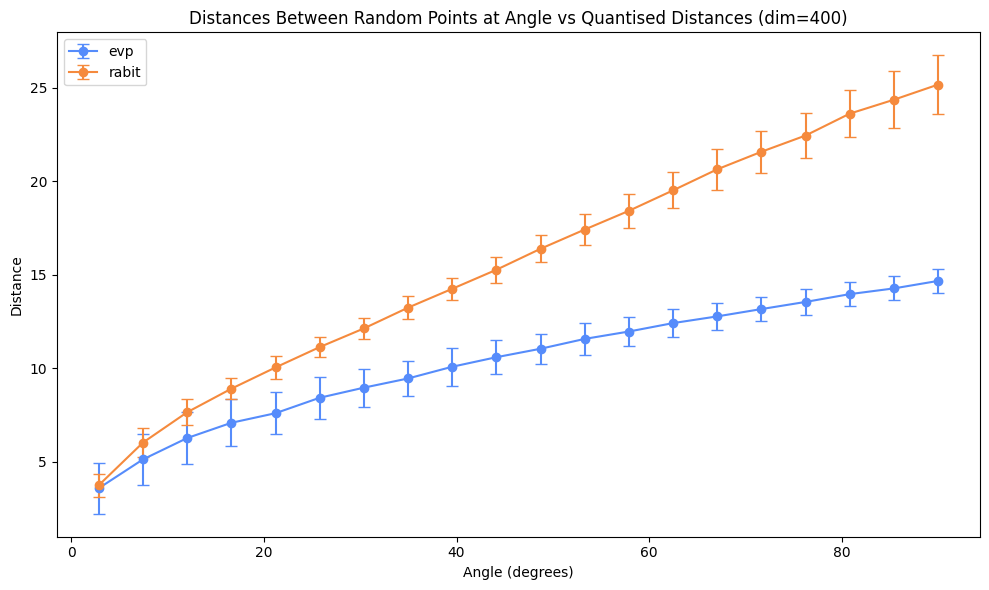

In [23]:
import numpy as np
import matplotlib.pyplot as plt

evp_dists = np.array(evp_dists)
rabit_dists = np.array(rabit_dists)

evp_mean = np.mean(evp_dists, axis=1)
evp_std = np.std(evp_dists, axis=1)

rabit_mean = np.mean(rabit_dists, axis=1)
rabit_std = np.std(rabit_dists, axis=1)

x = np.degrees(angles)

plt.figure(figsize=(10, 6))

plt.errorbar(
    x,
    evp_mean,
    yerr=evp_std,
    fmt="o-",
    capsize=4,
    label="evp",
)

plt.errorbar(
    x,
    rabit_mean,
    yerr=rabit_std,
    fmt="o-",
    capsize=4,
    label="rabit",
)

plt.title(f"Distances Between Random Points at Angle vs Quantised Distances (dim={dims})")

plt.xlabel("Angle (degrees)")
plt.ylabel("Distance")
plt.legend()

plt.tight_layout()
plt.show()